# Data Scientist Professional Practical Exam Submission

**Use this template to write up your summary for submission. Code in Python or R needs to be included.**


## 📝 Task List

Your written report should include both code, output and written text summaries of the following:
- Data Validation:   
  - Describe validation and cleaning steps for every column in the data 
- Exploratory Analysis:  
  - Include two different graphics showing single variables only to demonstrate the characteristics of data  
  - Include at least one graphic showing two or more variables to represent the relationship between features
  - Describe your findings
- Model Development
  - Include your reasons for selecting the models you use as well as a statement of the problem type
  - Code to fit the baseline and comparison models
- Model Evaluation
  - Describe the performance of the two models based on an appropriate metric
- Business Metrics
  - Define a way to compare your model performance to the business
  - Describe how your models perform using this approach
- Final summary including recommendations that the business should undertake

*Start writing report here..*

## ✅ When you have finished...
-  Publish your Workspace using the option on the left
-  Check the published version of your report:
	-  Can you see everything you want us to grade?
    -  Are all the graphics visible?
-  Review the grading rubric. Have you included everything that will be graded?
-  Head back to the [Certification Dashboard](https://app.datacamp.com/certification) to submit your practical exam report and record your presentation

In [41]:
import pandas as pd

df = pd.read_csv("recipe_site_traffic_2212.csv")

print(df.shape)
df.head()

(947, 8)


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


# Correcting recipe categories
standardised Chicken Breast to Chicken

In [42]:
df["category"] = df["category"].replace({
    "Chicken Breast": "Chicken"
})

print("Number of categories:", df["category"].nunique())

print(df["category"].value_counts())

Number of categories: 10
Chicken          172
Breakfast        106
Beverages         92
Lunch/Snacks      89
Potato            88
Pork              84
Vegetable         83
Dessert           83
Meat              79
One Dish Meal     71
Name: category, dtype: int64


# handling missing traffic labels
i am going to handle missing traffic labels as low

In [43]:
df["high_traffic"] = df["high_traffic"].fillna("Low")

print(df["high_traffic"].value_counts())

High    574
Low     373
Name: high_traffic, dtype: int64


# standardising the servings column
some entries contain additional text e.g 4 as a snack

In [44]:
df["is_snack"] = (
    df["servings"]
    .astype(str)
    .str.contains("as a snack", case=False)
    .astype(int)
)

df["servings"] = (
    df["servings"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

print(df["servings"].value_counts().sort_index())

print("Snack recipes:", df["is_snack"].sum())

1    175
2    183
4    391
6    198
Name: servings, dtype: int64
Snack recipes: 3


# investigating missing nutritional values

In [45]:
nutrition_columns = [
    "calories",
    "carbohydrate",
    "sugar",
    "protein"
]

print(df[nutrition_columns].isnull().sum())

calories        52
carbohydrate    52
sugar           52
protein         52
dtype: int64


# running final validation checks

In [46]:
print("Dataset shape:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Unique recipe IDs:", df["recipe"].nunique())

print("Unique categories:", df["category"].nunique())

print("\nTraffic distribution:")
print(df["high_traffic"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (947, 9)
Duplicate rows: 0
Unique recipe IDs: 947
Unique categories: 10

Traffic distribution:
High    574
Low     373
Name: high_traffic, dtype: int64

Missing values:
recipe           0
calories        52
carbohydrate    52
sugar           52
protein         52
category         0
servings         0
high_traffic     0
is_snack         0
dtype: int64


# analysing distribution of website traffic

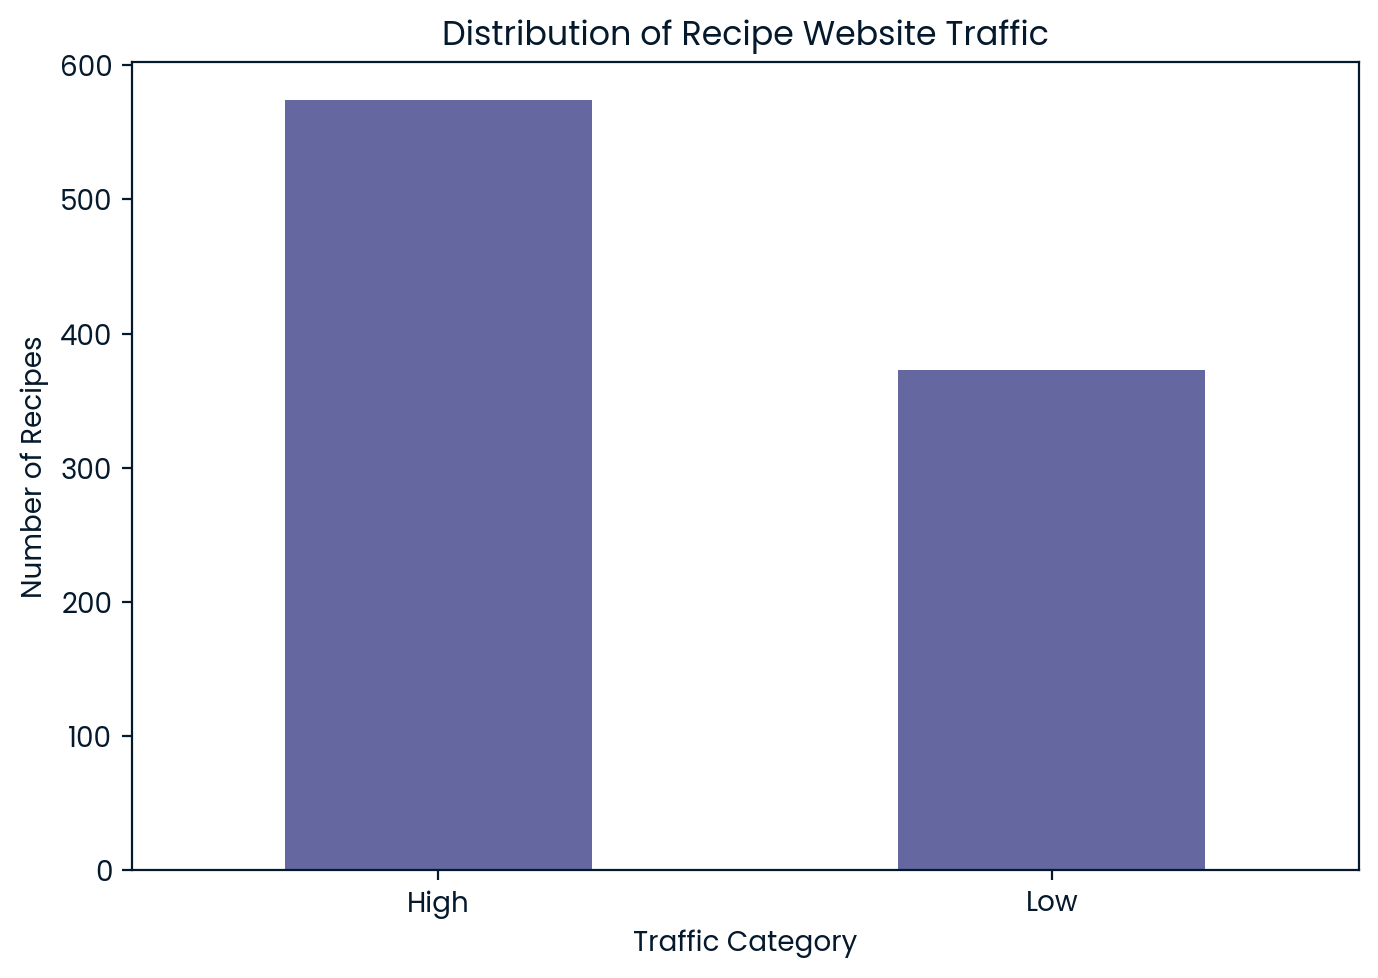

In [47]:
import matplotlib.pyplot as plt

traffic_counts = df["high_traffic"].value_counts()

plt.figure(figsize=(7, 5))
traffic_counts.plot(kind="bar")

plt.title("Distribution of Recipe Website Traffic")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Recipes")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Investigate the distribution of recipes across categories

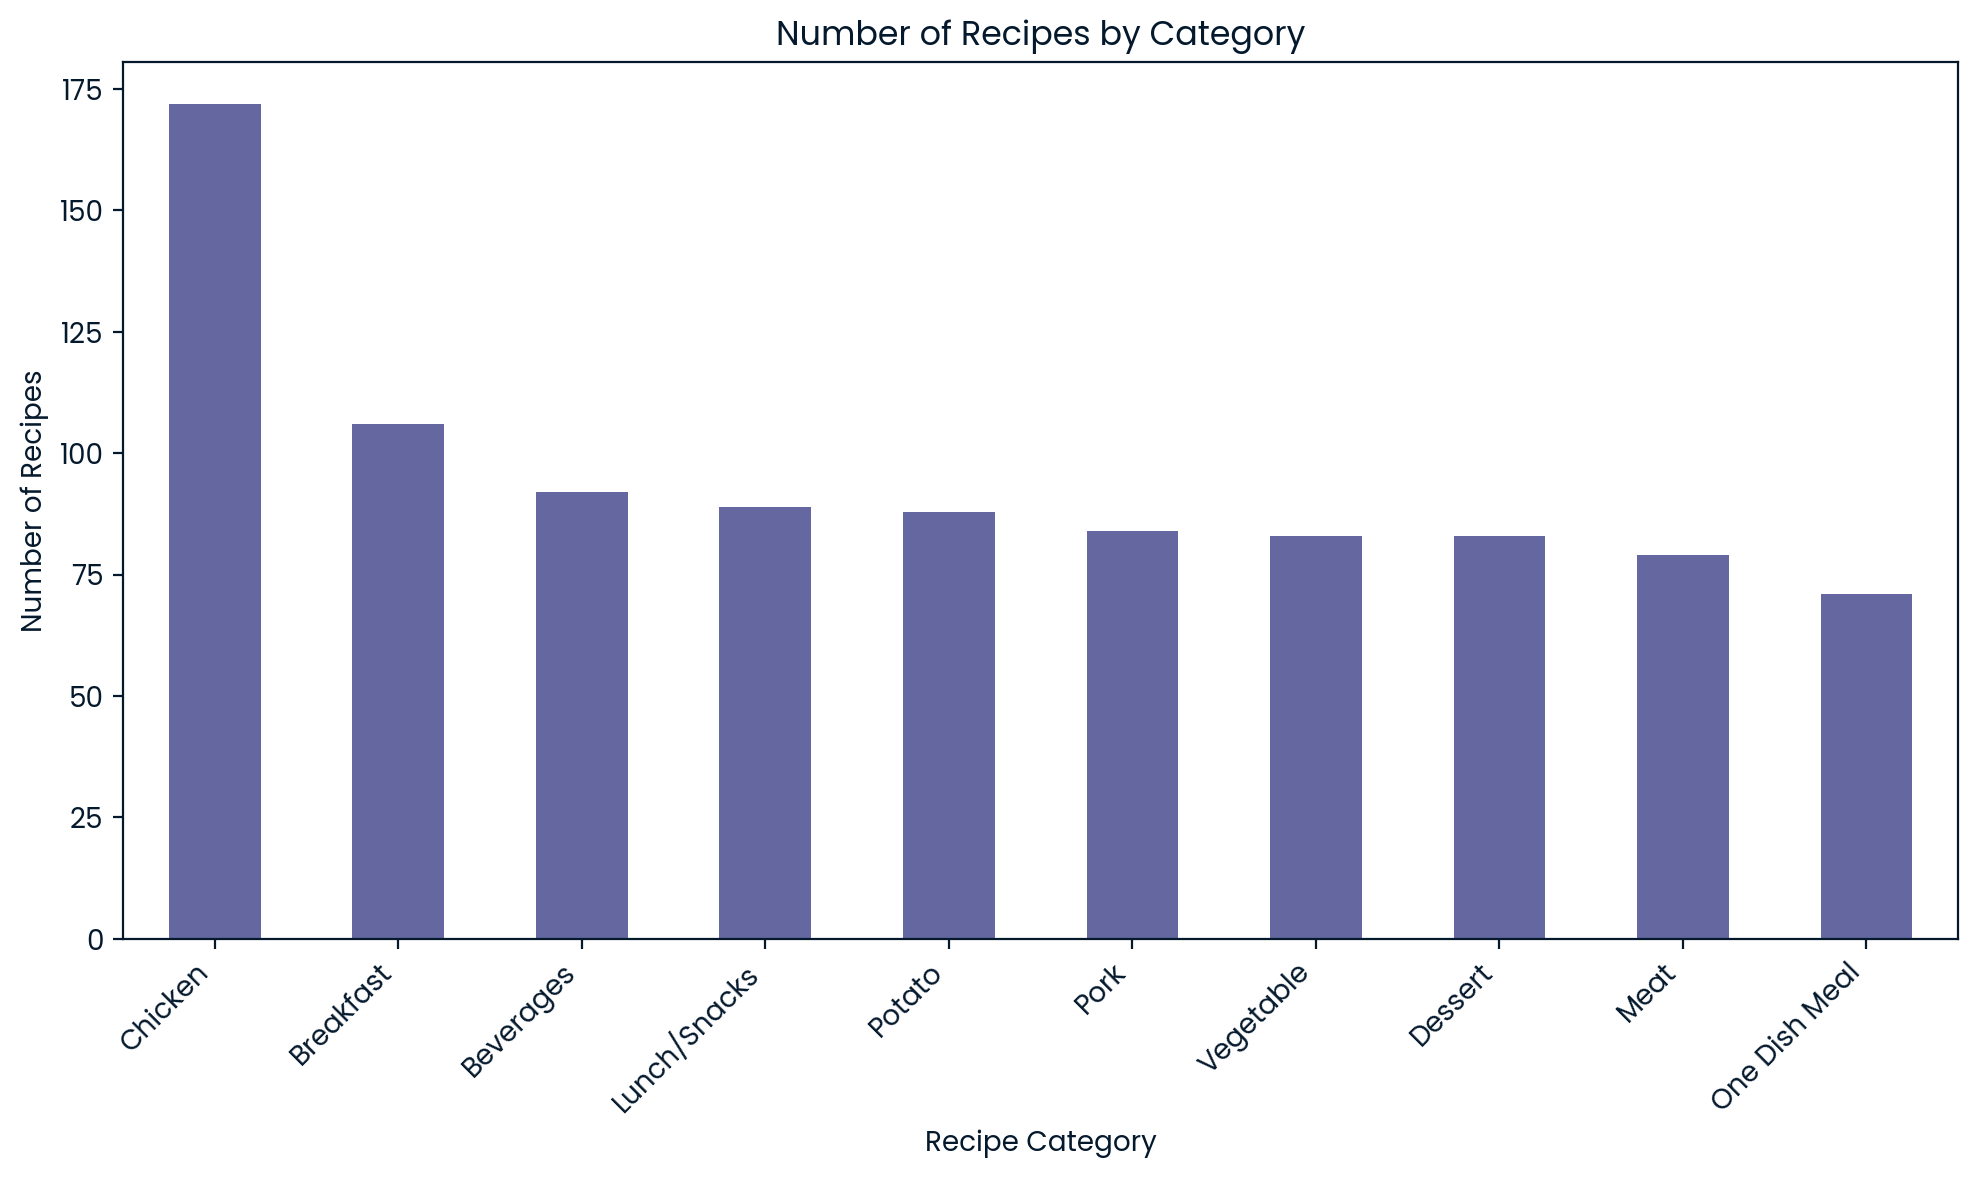

In [48]:
plt.figure(figsize=(10, 6))

df["category"].value_counts().plot(kind="bar")

plt.title("Number of Recipes by Category")
plt.xlabel("Recipe Category")
plt.ylabel("Number of Recipes")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Which recipe categories are associated with high website traffic

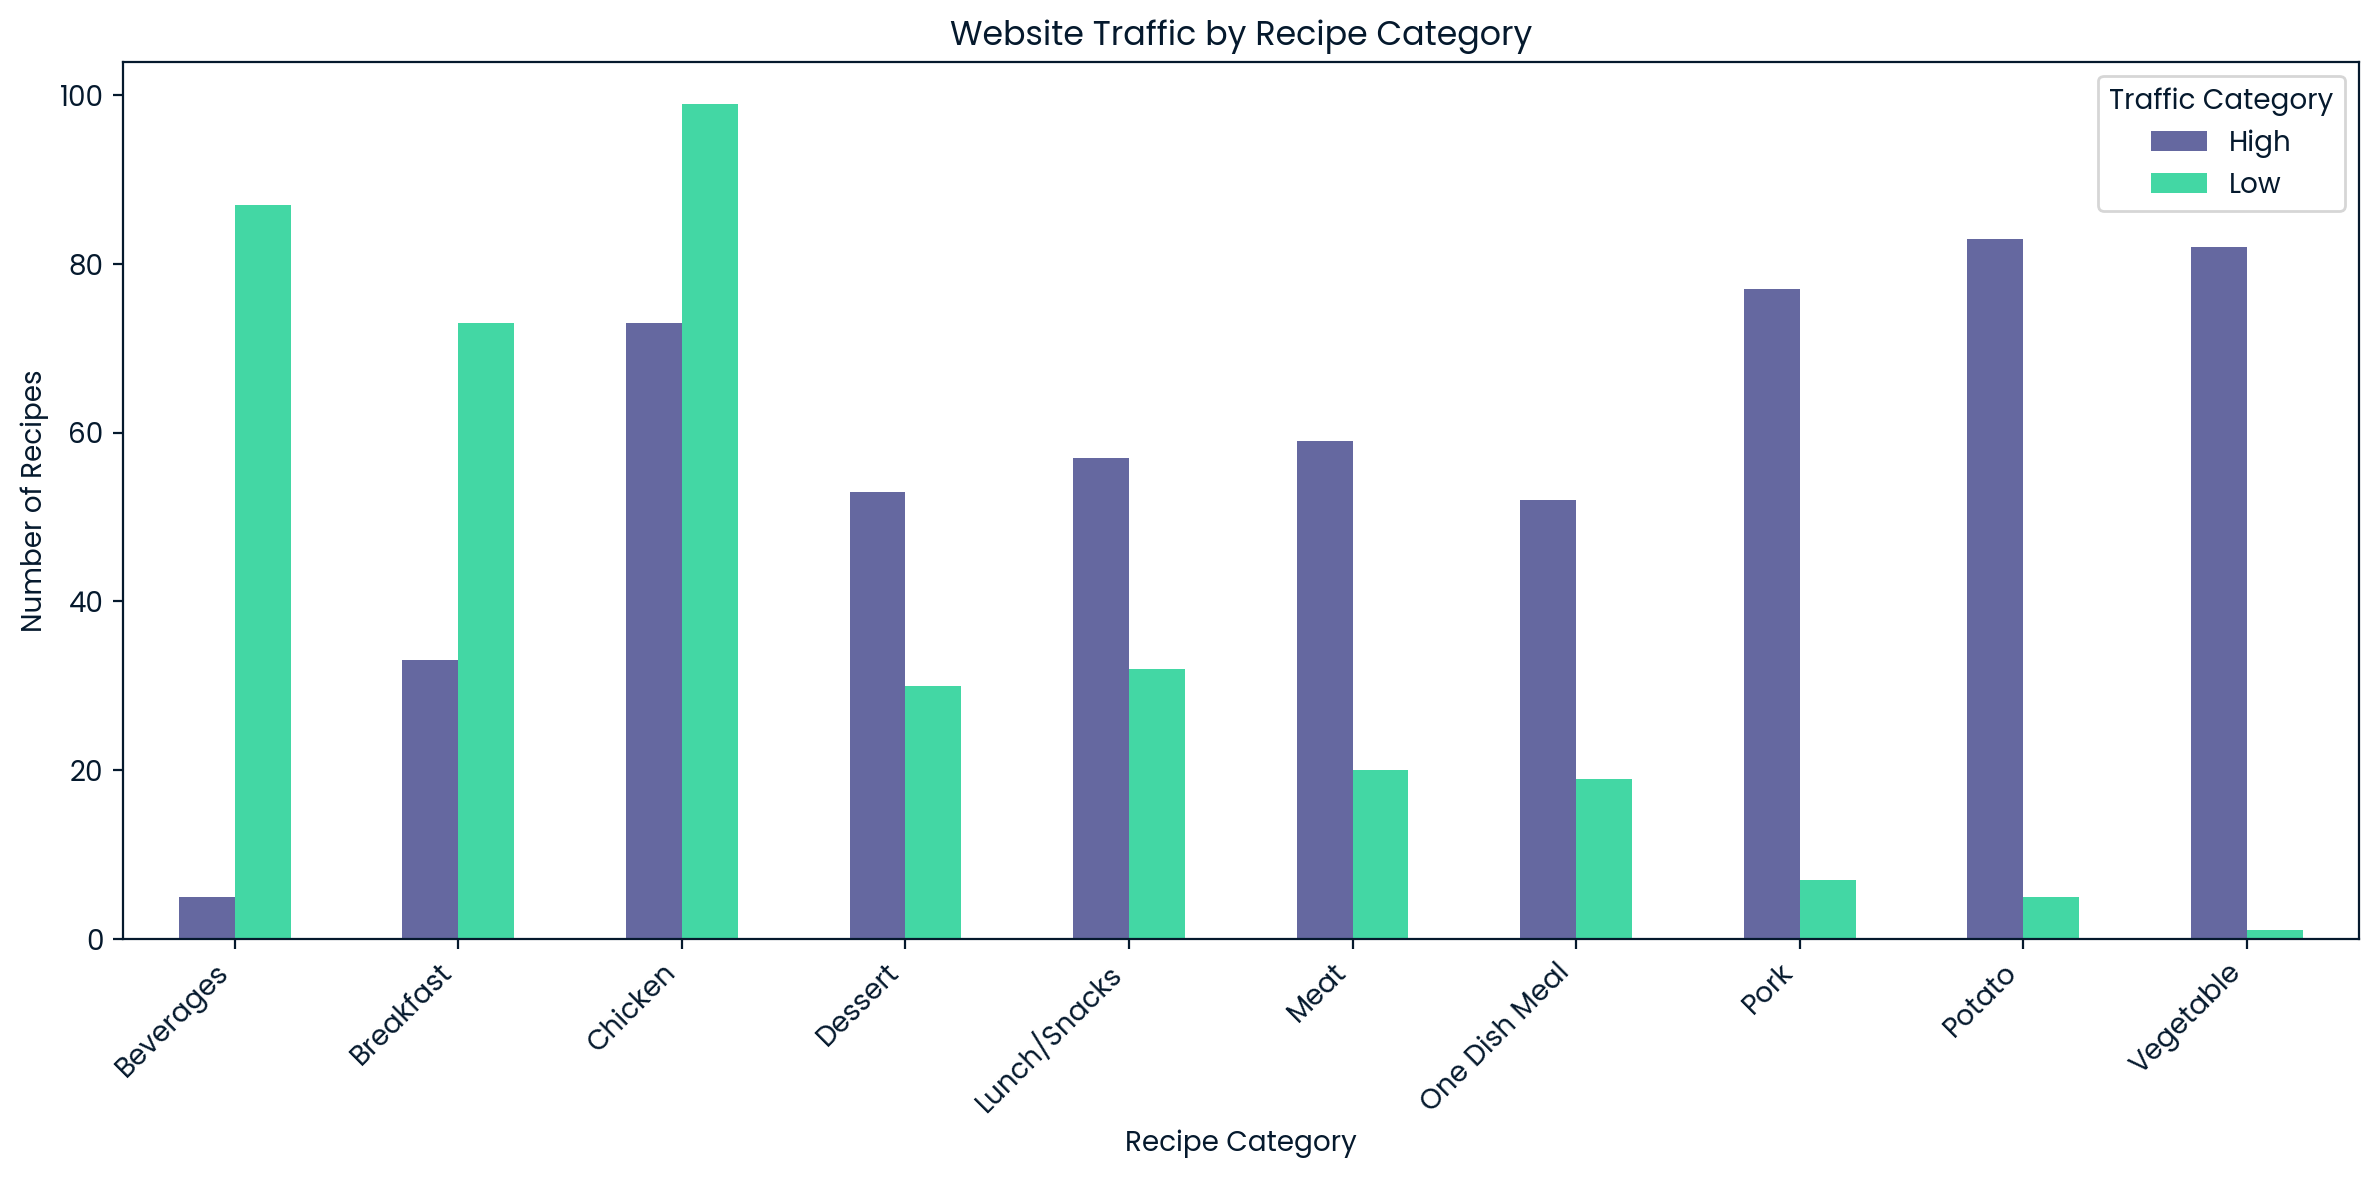

In [49]:
traffic_by_category = pd.crosstab(
    df["category"],
    df["high_traffic"]
)

traffic_by_category.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Website Traffic by Recipe Category")
plt.xlabel("Recipe Category")
plt.ylabel("Number of Recipes")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Traffic Category")

plt.tight_layout()
plt.show()

calculate high traffic rate by category

In [50]:
category_traffic = pd.crosstab(
    df["category"],
    df["high_traffic"]
)

category_traffic["total_recipes"] = (
    category_traffic.sum(axis=1)
)

category_traffic["high_traffic_rate"] = (
    category_traffic["High"]
    / category_traffic["total_recipes"]
    * 100
)

category_traffic = category_traffic.sort_values(
    "high_traffic_rate",
    ascending=False
)

print(category_traffic.round(2))

high_traffic   High  Low  total_recipes  high_traffic_rate
category                                                  
Vegetable        82    1             83              98.80
Potato           83    5             88              94.32
Pork             77    7             84              91.67
Meat             59   20             79              74.68
One Dish Meal    52   19             71              73.24
Lunch/Snacks     57   32             89              64.04
Dessert          53   30             83              63.86
Chicken          73   99            172              42.44
Breakfast        33   73            106              31.13
Beverages         5   87             92               5.43


Best performing recipe categories

In [51]:
print("Top 3 categories by high-traffic rate:")
print(
    category_traffic[
        ["High", "Low", "total_recipes", "high_traffic_rate"]
    ].head(3).round(2)
)

print("\nBottom 3 categories by high-traffic rate:")
print(
    category_traffic[
        ["High", "Low", "total_recipes", "high_traffic_rate"]
    ].tail(3).round(2)
)

Top 3 categories by high-traffic rate:
high_traffic  High  Low  total_recipes  high_traffic_rate
category                                                 
Vegetable       82    1             83              98.80
Potato          83    5             88              94.32
Pork            77    7             84              91.67

Bottom 3 categories by high-traffic rate:
high_traffic  High  Low  total_recipes  high_traffic_rate
category                                                 
Chicken         73   99            172              42.44
Breakfast       33   73            106              31.13
Beverages        5   87             92               5.43


Calories by traffic category

<Figure size 800x500 with 0 Axes>

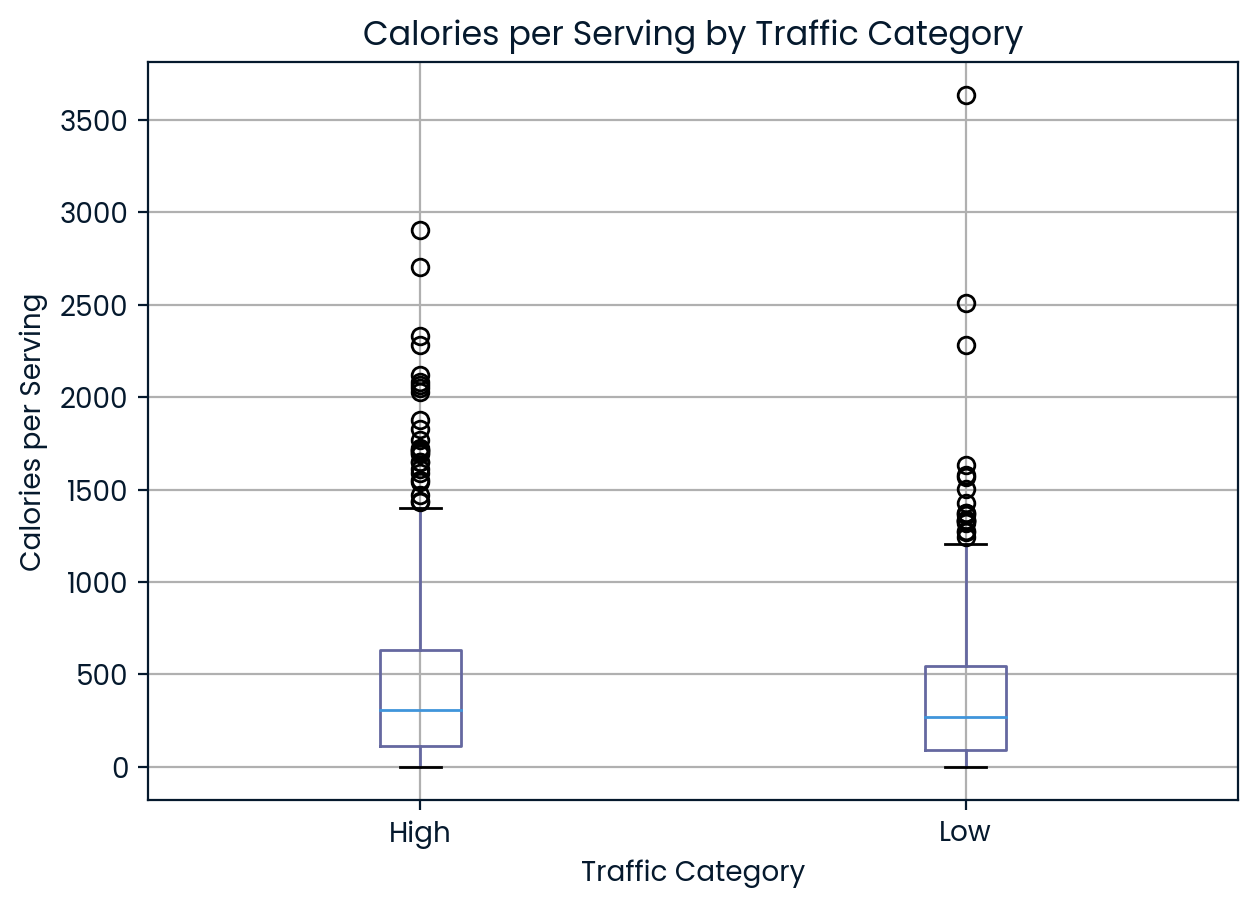

In [52]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="calories",
    by="high_traffic"
)

plt.title("Calories per Serving by Traffic Category")
plt.suptitle("")
plt.xlabel("Traffic Category")
plt.ylabel("Calories per Serving")

plt.tight_layout()
plt.show()

In [53]:
print(df.columns.tolist())

['recipe', 'calories', 'carbohydrate', 'sugar', 'protein', 'category', 'servings', 'high_traffic', 'is_snack']


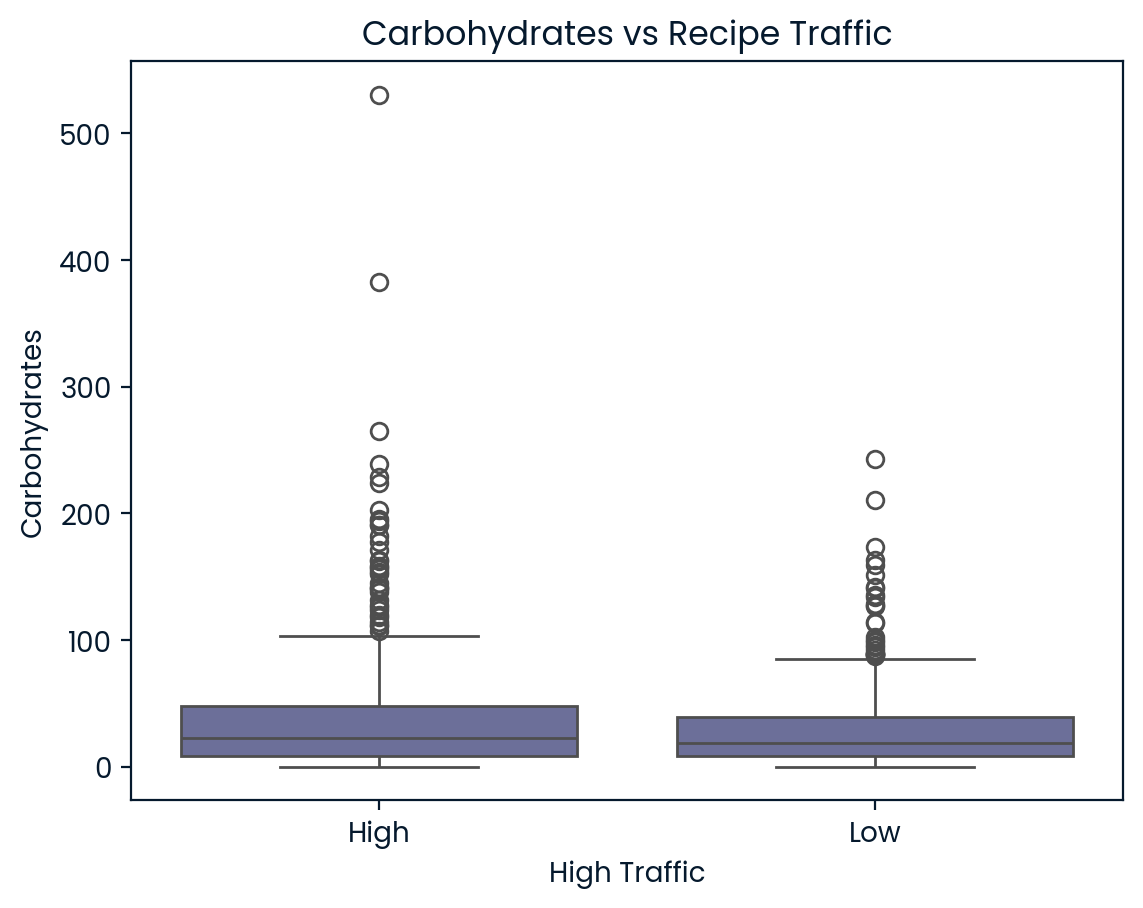

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="high_traffic", y="carbohydrate")

plt.title("Carbohydrates vs Recipe Traffic")
plt.xlabel("High Traffic")
plt.ylabel("Carbohydrates")

plt.show()



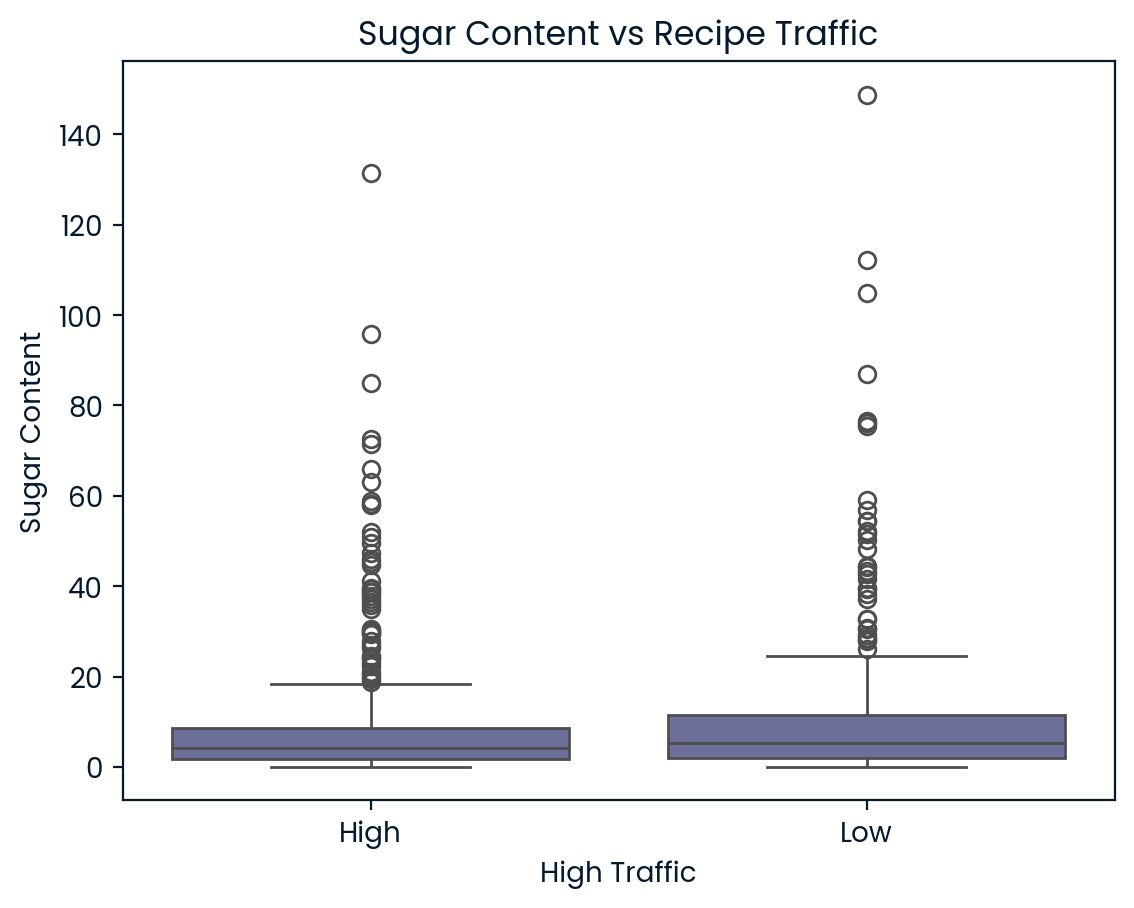

In [55]:
sns.boxplot(data=df, x="high_traffic", y="sugar")

plt.title("Sugar Content vs Recipe Traffic")
plt.xlabel("High Traffic")
plt.ylabel("Sugar Content")

plt.show()



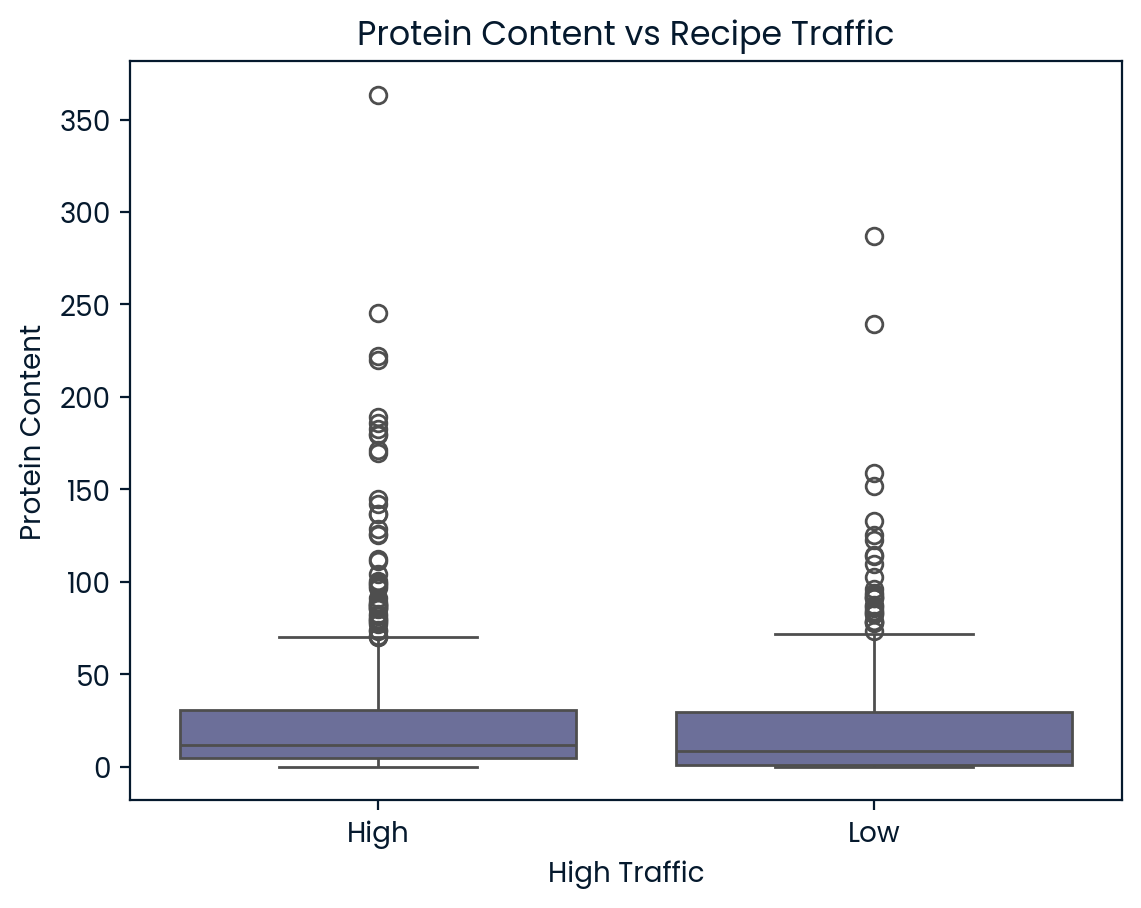

In [56]:
sns.boxplot(data=df, x="high_traffic", y="protein")

plt.title("Protein Content vs Recipe Traffic")
plt.xlabel("High Traffic")
plt.ylabel("Protein Content")

plt.show()



Creating a correlation heatmap

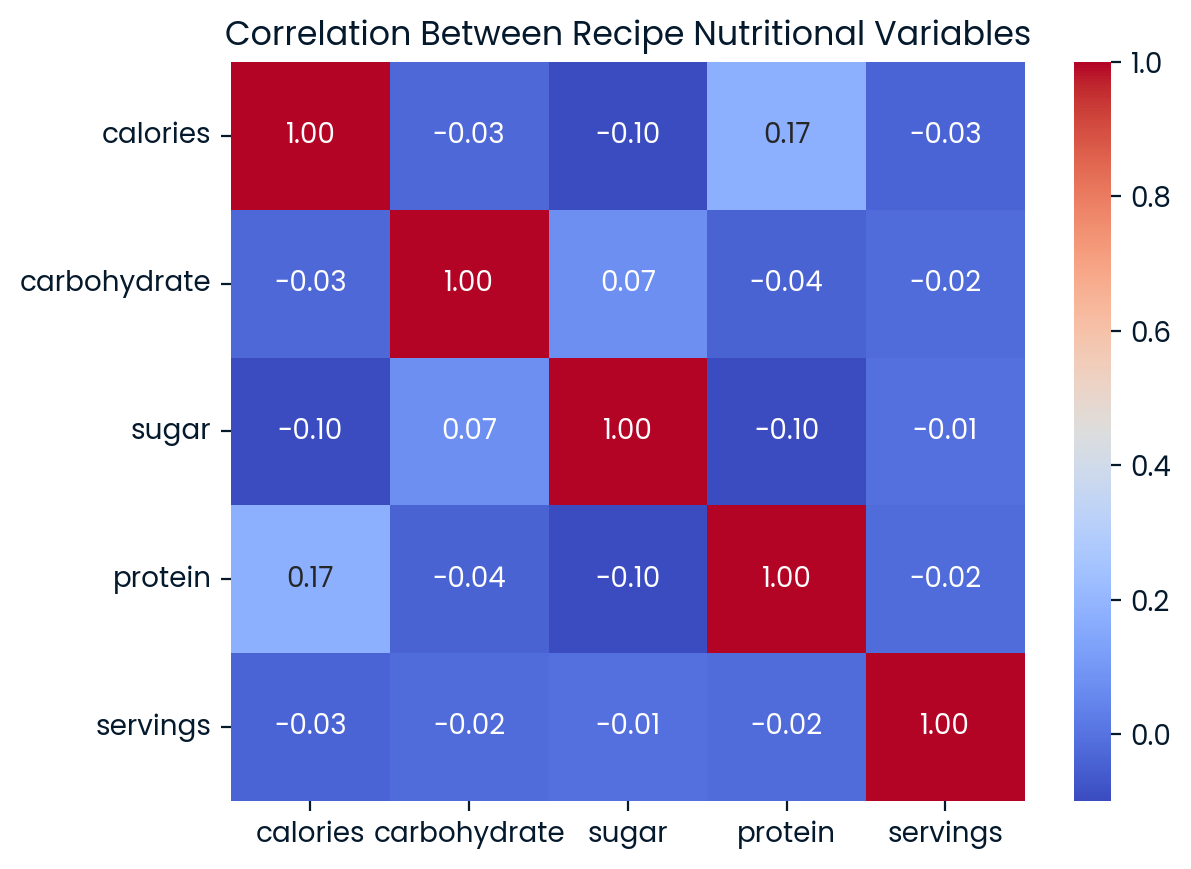

In [57]:

import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df[
    ["calories", "carbohydrate", "sugar", "protein", "servings"]
]

correlation_matrix = numeric_df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Recipe Nutritional Variables")
plt.show()



Checking traffic class distribution

In [58]:
print(df["high_traffic"].value_counts())

print("\nTraffic percentages:")
print(df["high_traffic"].value_counts(normalize=True) * 100)



High    574
Low     373
Name: high_traffic, dtype: int64

Traffic percentages:
High    60.61246
Low     39.38754
Name: high_traffic, dtype: float64


checking for missing values

In [59]:
print(df.isnull().sum())

recipe           0
calories        52
carbohydrate    52
sugar           52
protein         52
category         0
servings         0
high_traffic     0
is_snack         0
dtype: int64


In [60]:
# Fill missing nutritional values with each column's median
nutritional_columns = [
    "calories",
    "carbohydrate",
    "sugar",
    "protein"
]

for column in nutritional_columns:
    df[column] = df[column].fillna(df[column].median())

# Check missing values again
print(df.isnull().sum())

recipe          0
calories        0
carbohydrate    0
sugar           0
protein         0
category        0
servings        0
high_traffic    0
is_snack        0
dtype: int64


In [61]:
# Select the features
X = df[
    [
        "calories",
        "carbohydrate",
        "sugar",
        "protein",
        "category",
        "servings",
        "is_snack"
    ]
]

# Select the target
y = df["high_traffic"]

# Check the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature rows:")
print(X.head())

print("\nFirst five target values:")
print(y.head())

Features shape: (947, 7)
Target shape: (947,)

First five feature rows:
   calories  carbohydrate  sugar  protein   category  servings  is_snack
0    288.55         21.48   4.55    10.80       Pork         6         0
1     35.48         38.56   0.66     0.92     Potato         4         0
2    914.28         42.68   3.09     2.88  Breakfast         1         0
3     97.03         30.56  38.63     0.02  Beverages         4         0
4     27.05          1.85   0.80     0.53  Beverages         4         0

First five target values:
0    High
1    High
2     Low
3    High
4     Low
Name: high_traffic, dtype: object


In [62]:
# Convert categorical features into numerical columns
X_encoded = pd.get_dummies(
    X,
    columns=["category"],
    dtype=int
)

# Check the encoded features
print("Original features shape:", X.shape)
print("Encoded features shape:", X_encoded.shape)

print("\nEncoded column names:")
print(X_encoded.columns.tolist())

print("\nFirst five encoded rows:")
print(X_encoded.head())

Original features shape: (947, 7)
Encoded features shape: (947, 16)

Encoded column names:
['calories', 'carbohydrate', 'sugar', 'protein', 'servings', 'is_snack', 'category_Beverages', 'category_Breakfast', 'category_Chicken', 'category_Dessert', 'category_Lunch/Snacks', 'category_Meat', 'category_One Dish Meal', 'category_Pork', 'category_Potato', 'category_Vegetable']

First five encoded rows:
   calories  carbohydrate  ...  category_Potato  category_Vegetable
0    288.55         21.48  ...                0                   0
1     35.48         38.56  ...                1                   0
2    914.28         42.68  ...                0                   0
3     97.03         30.56  ...                0                   0
4     27.05          1.85  ...                0                   0

[5 rows x 16 columns]


In [63]:
from sklearn.model_selection import train_test_split

# Split the features and target
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())



Training features: (757, 16)
Testing features: (190, 16)

Training target distribution:
High    459
Low     298
Name: high_traffic, dtype: int64

Testing target distribution:
High    115
Low      75
Name: high_traffic, dtype: int64


In [64]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")



Decision Tree model trained successfully!


In [65]:
# Predict traffic for unseen recipes
y_pred = model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual traffic values:")
print(y_test.iloc[:10].values)



First 10 predictions:
['High' 'High' 'High' 'Low' 'Low' 'Low' 'High' 'High' 'Low' 'High']

First 10 actual traffic values:
['Low' 'High' 'Low' 'High' 'Low' 'Low' 'High' 'High' 'High' 'High']


In [66]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")



Model Accuracy: 73.68%


In [67]:

from sklearn.metrics import classification_report

# Evaluate performance for each traffic category
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

        High       0.76      0.83      0.79       115
         Low       0.70      0.59      0.64        75

    accuracy                           0.74       190
   macro avg       0.73      0.71      0.72       190
weighted avg       0.73      0.74      0.73       190



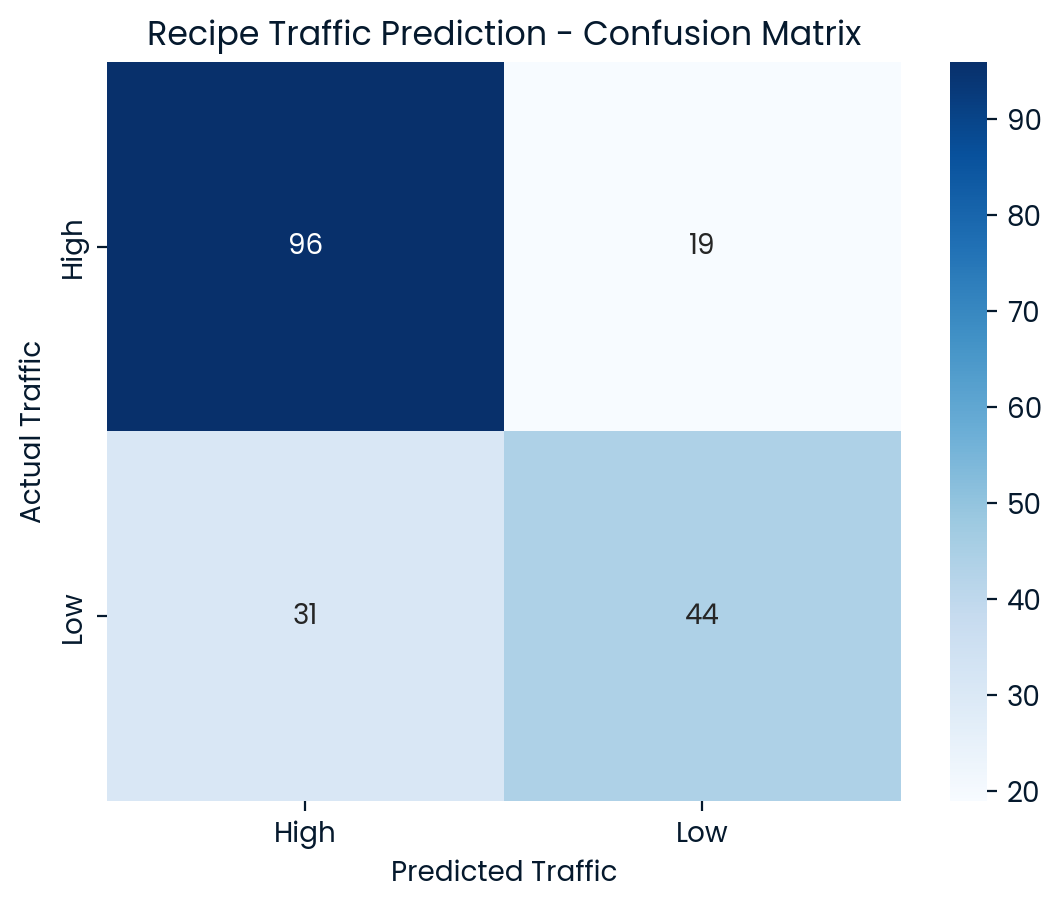

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["High", "Low"]
)

# Plot the confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["High", "Low"],
    yticklabels=["High", "Low"]
)

plt.xlabel("Predicted Traffic")
plt.ylabel("Actual Traffic")
plt.title("Recipe Traffic Prediction - Confusion Matrix")
plt.show()


In [69]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Compare accuracy
print("Decision Tree Accuracy:",
      f"{accuracy_score(y_test, y_pred) * 100:.2f}%")

print("Random Forest Accuracy:",
      f"{accuracy_score(y_test, rf_pred) * 100:.2f}%")

# Examine the Random Forest performance
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))



Decision Tree Accuracy: 73.68%
Random Forest Accuracy: 76.84%

Random Forest Classification Report:
              precision    recall  f1-score   support

        High       0.82      0.79      0.81       115
         Low       0.70      0.73      0.71        75

    accuracy                           0.77       190
   macro avg       0.76      0.76      0.76       190
weighted avg       0.77      0.77      0.77       190



               Feature  Importance
    category_Beverages    0.212432
    category_Vegetable    0.147820
       category_Potato    0.110167
               protein    0.106024
    category_Breakfast    0.082341
      category_Chicken    0.072958
         category_Pork    0.072031
              calories    0.057436
                 sugar    0.051246
          carbohydrate    0.045141
              servings    0.018770
         category_Meat    0.009512
 category_Lunch/Snacks    0.005780
category_One Dish Meal    0.004701
      category_Dessert    0.003600
              is_snack    0.000040


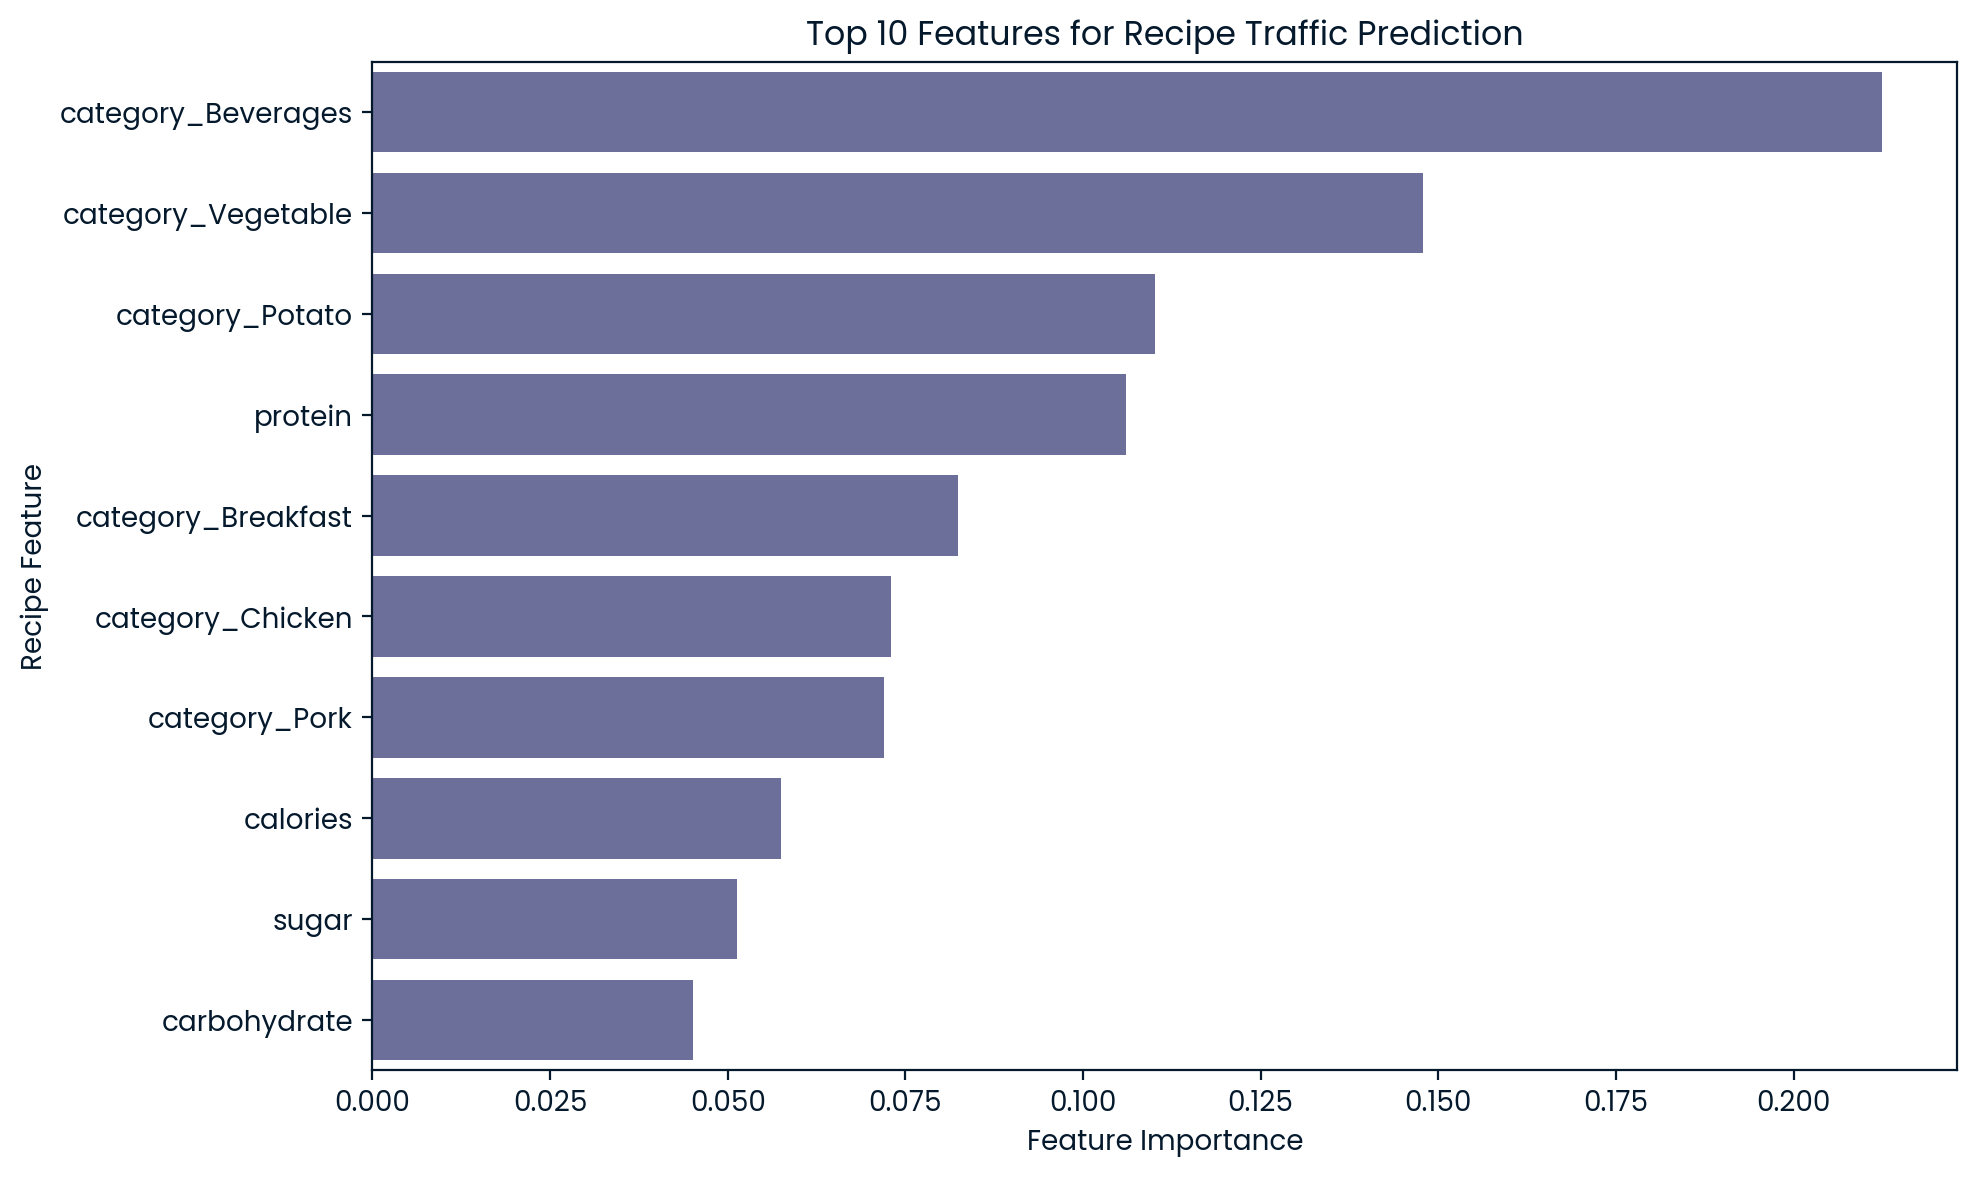

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the results
print(importance_df.to_string(index=False))

# Visualise the top 10 features
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Recipe Traffic Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Recipe Feature")
plt.tight_layout()
plt.show()



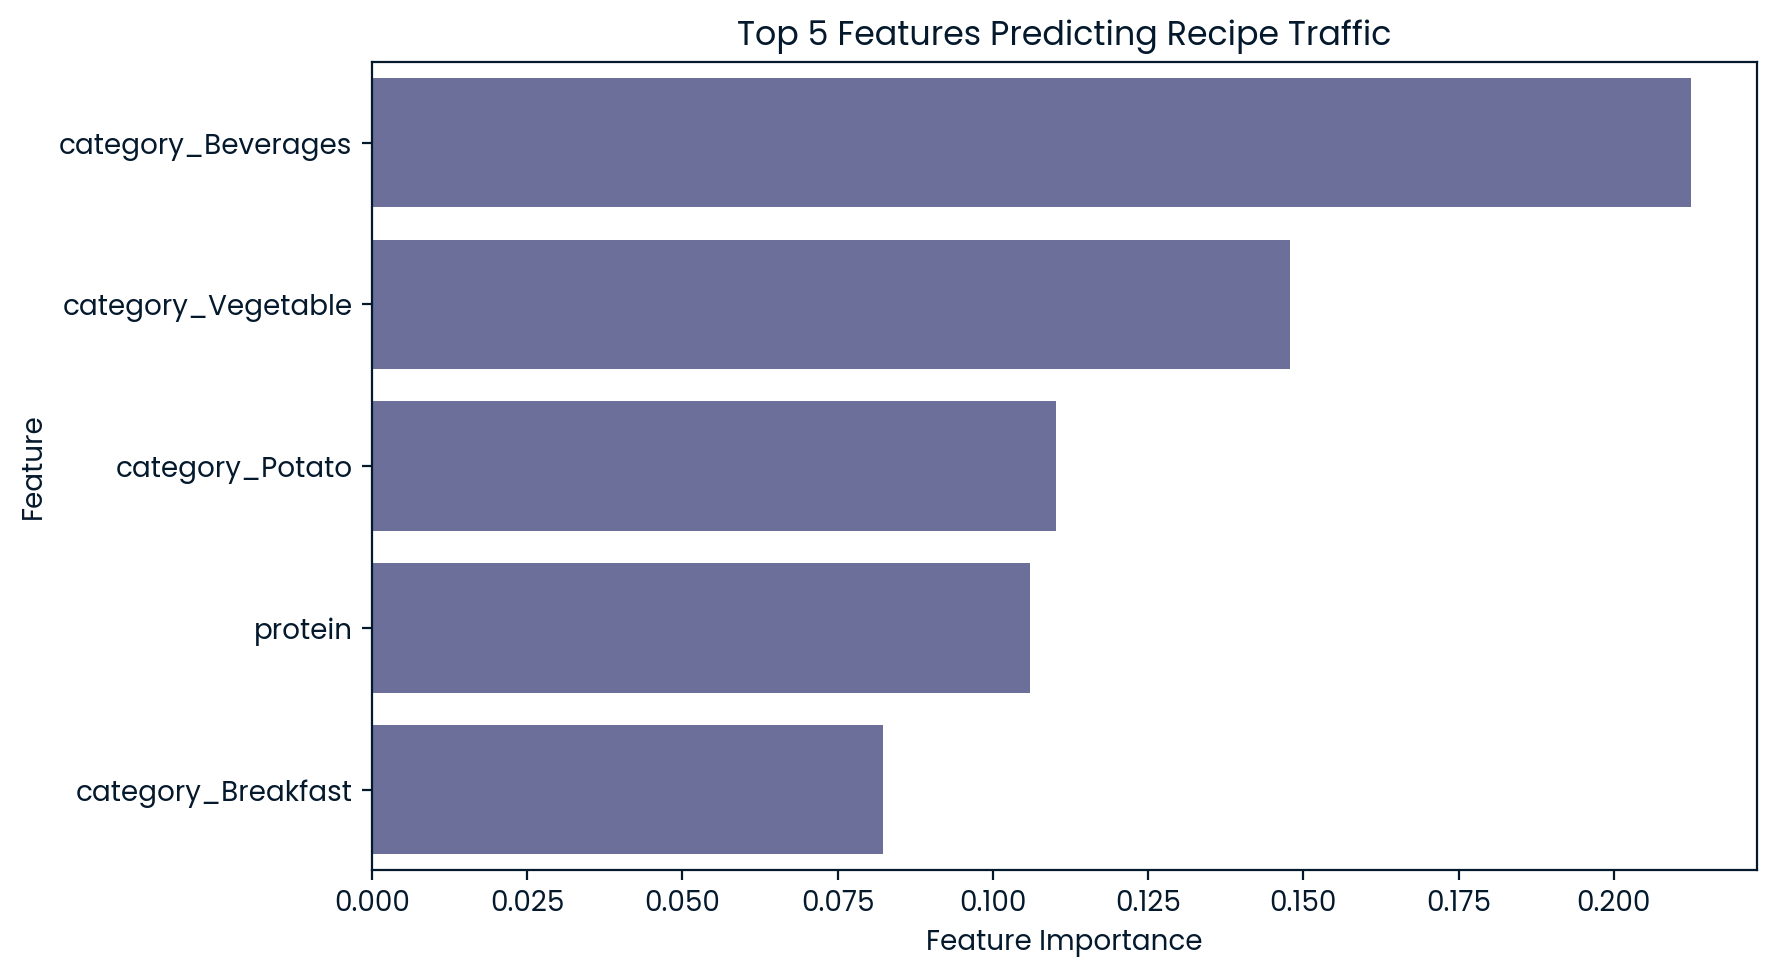

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

top_five = importance_df.head(5)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_five,
    x="Importance",
    y="Feature"
)

plt.title("Top 5 Features Predicting Recipe Traffic")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()



In [72]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X_encoded,
    y,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)
print("Average accuracy:", f"{cv_scores.mean() * 100:.2f}%")

Cross-validation scores: [0.74736842 0.71578947 0.75661376 0.78835979 0.76719577]
Average accuracy: 75.51%


In [73]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Decision Tree
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_scores = cross_val_score(
    tree_model,
    X_encoded,
    y,
    cv=5,
    scoring="accuracy"
)

# Random Forest
forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

forest_scores = cross_val_score(
    forest_model,
    X_encoded,
    y,
    cv=5,
    scoring="accuracy"
)

# Compare average accuracy
print("Decision Tree Average Accuracy:",
      f"{tree_scores.mean() * 100:.2f}%")

print("Random Forest Average Accuracy:",
      f"{forest_scores.mean() * 100:.2f}%")

Decision Tree Average Accuracy: 72.97%
Random Forest Average Accuracy: 75.51%


In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_scores = cross_val_score(
    log_model,
    X_encoded,
    y,
    cv=5,
    scoring="accuracy"
)

print(
    "Logistic Regression Average Accuracy:",
    f"{log_scores.mean() * 100:.2f}%"
)

Logistic Regression Average Accuracy: 76.03%


In [75]:
from sklearn.metrics import classification_report, accuracy_score

# Train Logistic Regression on the training data
log_model.fit(X_train, y_train)

# Predict traffic on the unseen test data
log_pred = log_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Test Accuracy:",
      f"{accuracy_score(y_test, log_pred) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, log_pred))

Logistic Regression Test Accuracy: 75.79%

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.79      0.80       115
         Low       0.69      0.71      0.70        75

    accuracy                           0.76       190
   macro avg       0.75      0.75      0.75       190
weighted avg       0.76      0.76      0.76       190



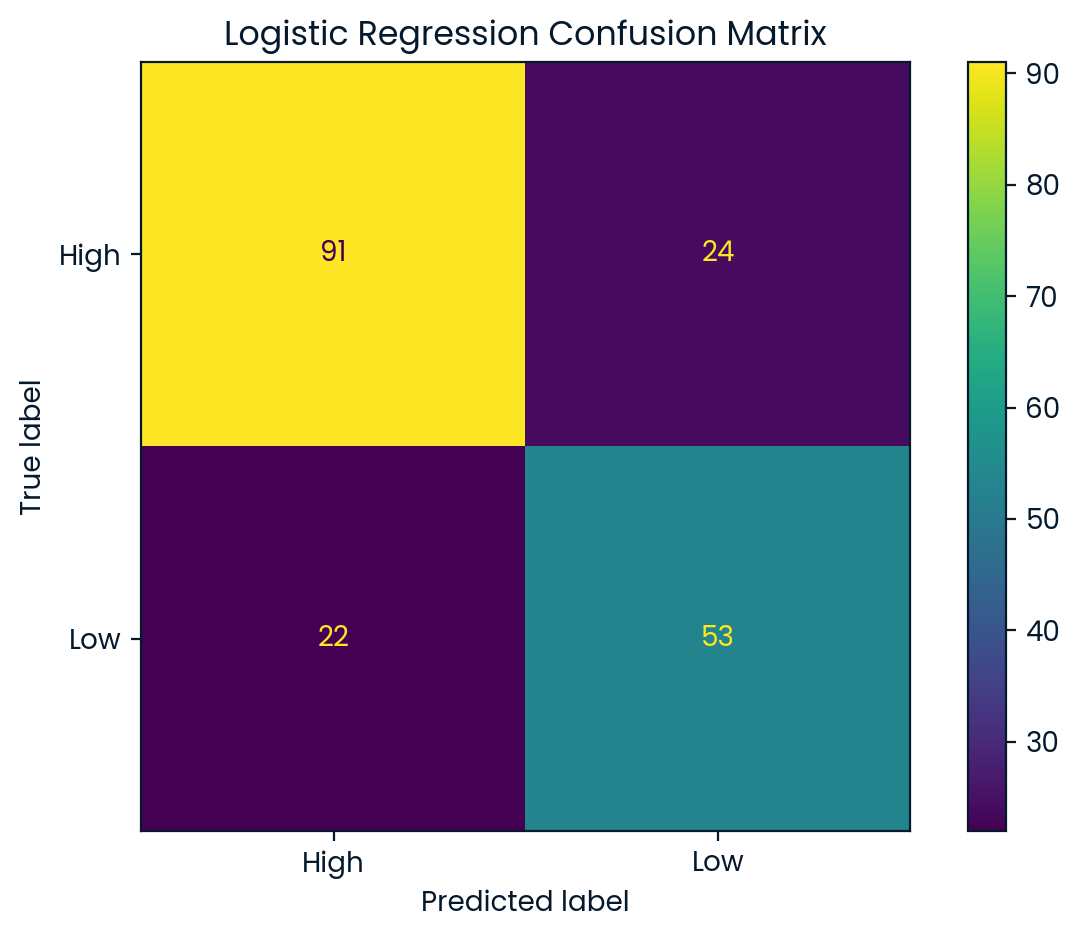

[[91 24]
 [22 53]]


In [76]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    log_pred,
    labels=["High", "Low"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["High", "Low"]
)

display.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

print(cm)

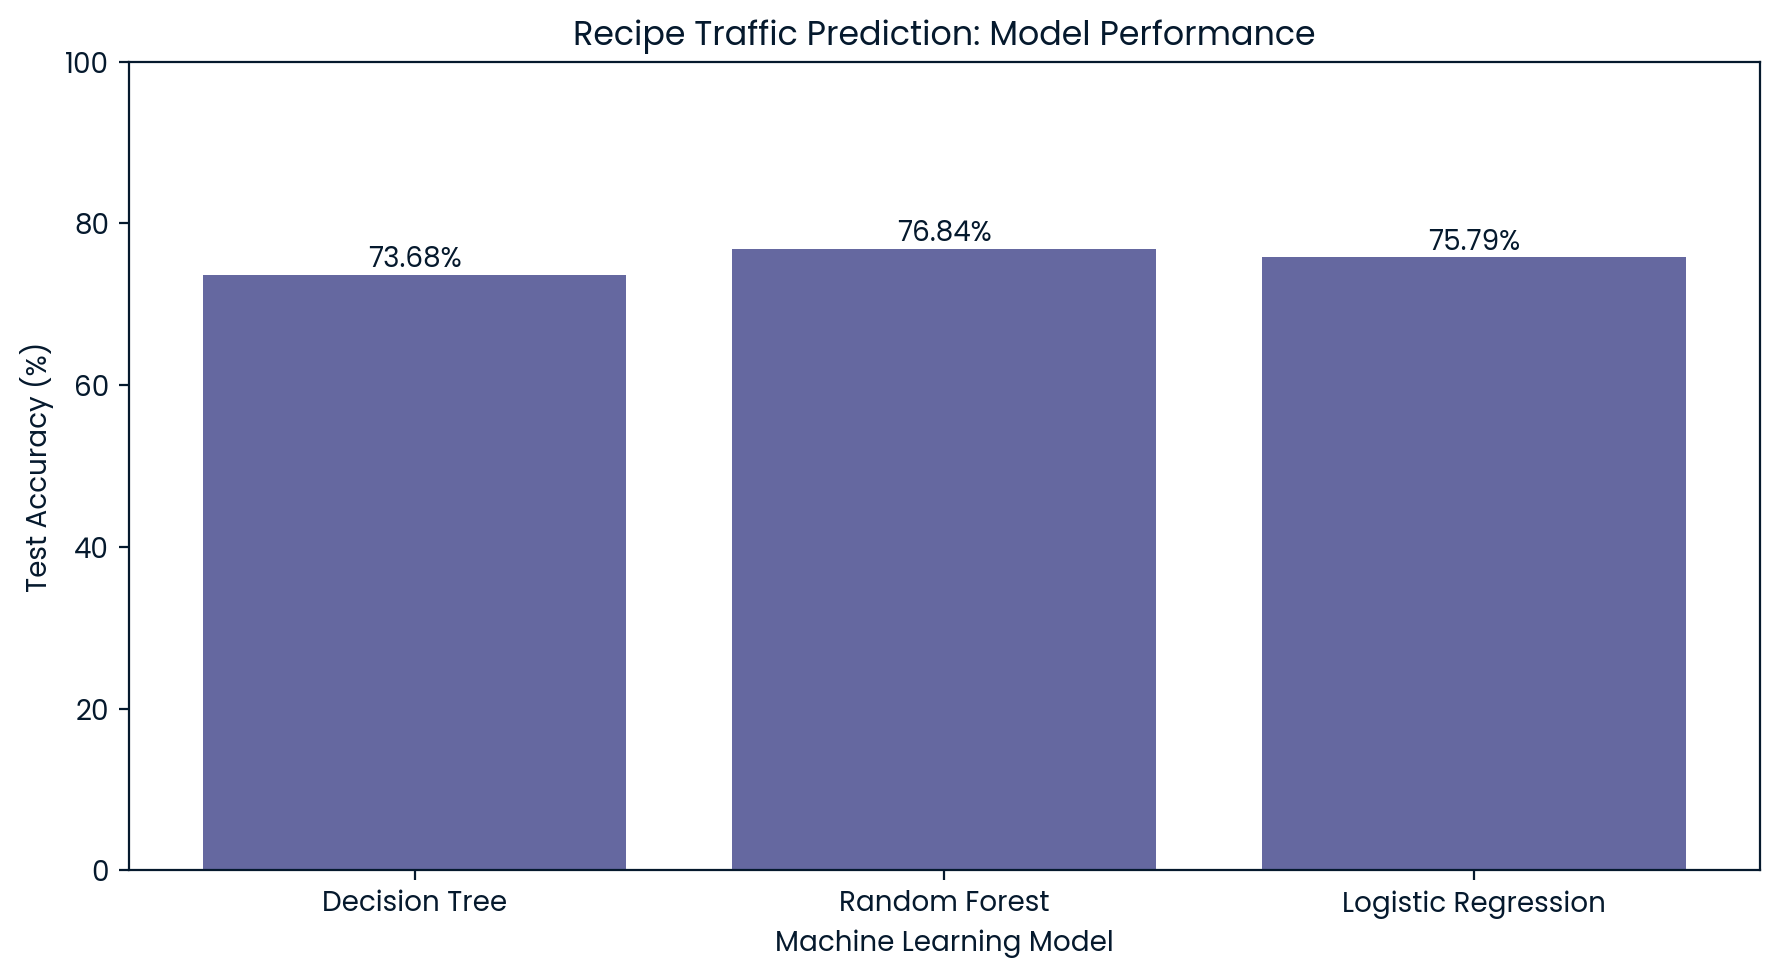

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression"
    ],
    "Test Accuracy": [
        73.68,
        76.84,
        75.79
    ]
})

plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["Test Accuracy"]
)

plt.title("Recipe Traffic Prediction: Model Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, accuracy in enumerate(model_results["Test Accuracy"]):
    plt.text(i, accuracy + 1, f"{accuracy:.2f}%", ha="center")

plt.tight_layout()
plt.show()

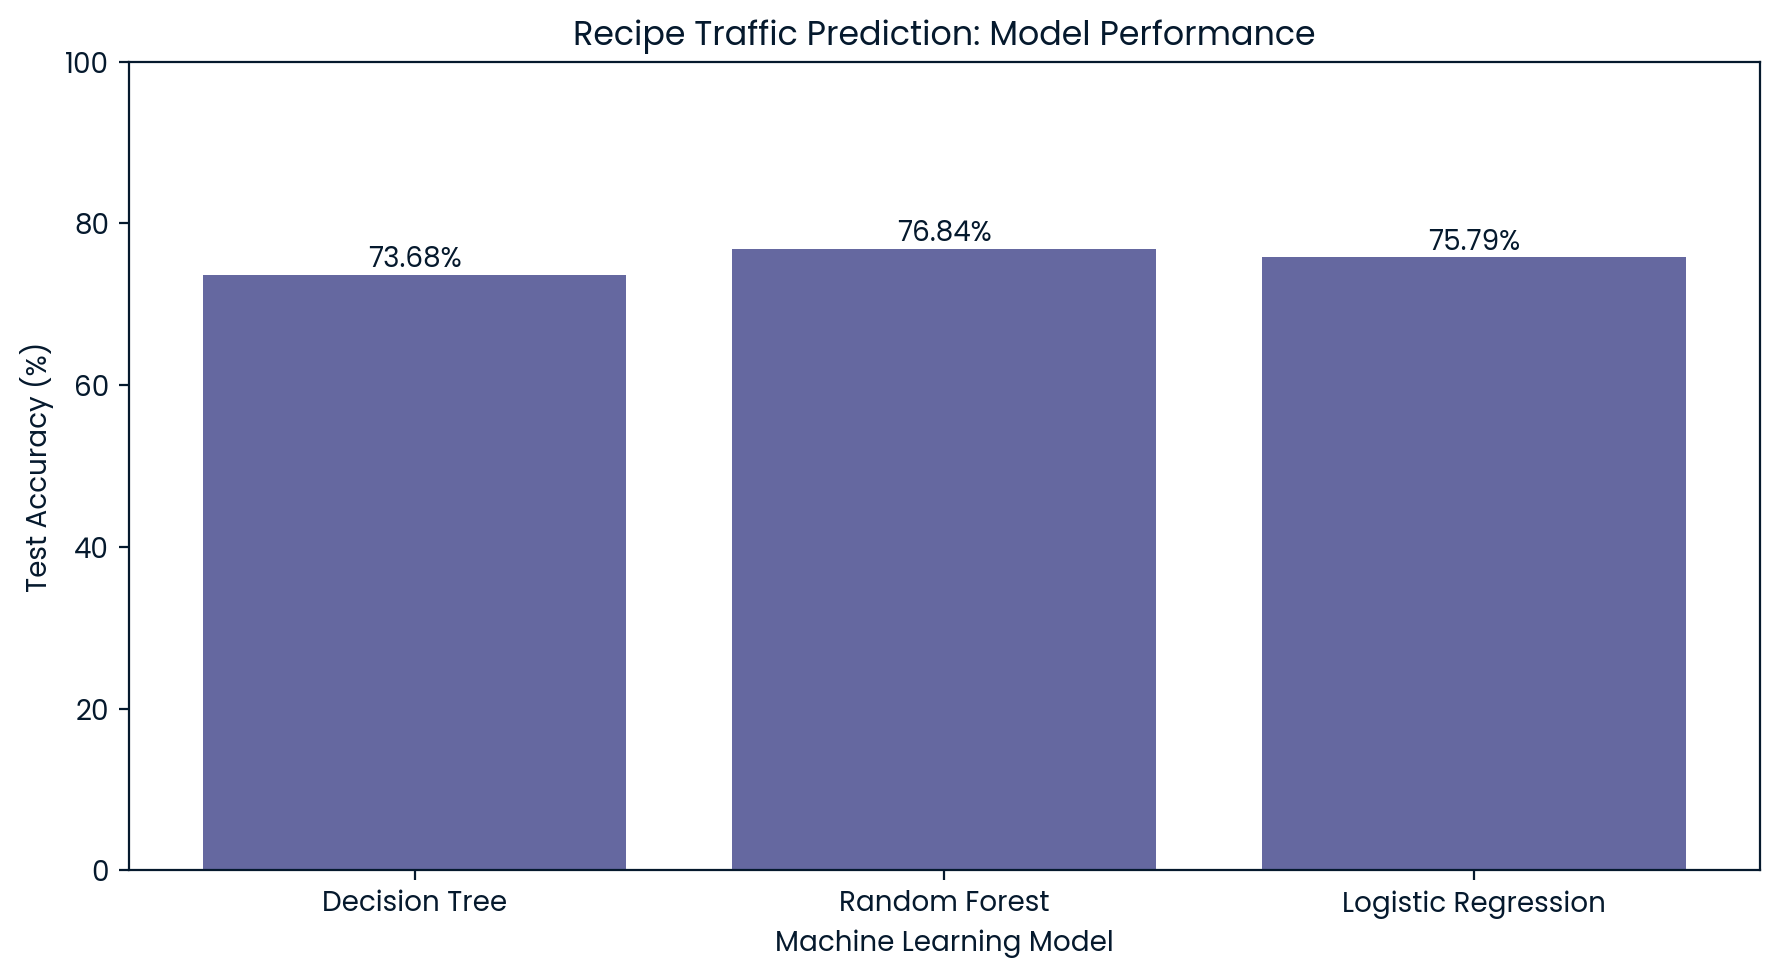

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression"
    ],
    "Test Accuracy": [
        73.68,
        76.84,
        75.79
    ]
})

plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["Test Accuracy"]
)

plt.title("Recipe Traffic Prediction: Model Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, accuracy in enumerate(model_results["Test Accuracy"]):
    plt.text(i, accuracy + 1, f"{accuracy:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [79]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression"
    ],
    "Cross_Validation_Accuracy": [
        72.97,
        75.51,
        76.03
    ],
    "Test_Accuracy": [
        73.68,
        76.84,
        75.79
    ]
})

results = results.sort_values(
    by="Cross_Validation_Accuracy",
    ascending=False
)

print(results.to_string(index=False))

results.to_csv(
    "recipe_traffic_model_results.csv",
    index=False
)

print("\nResults saved successfully!")

              Model  Cross_Validation_Accuracy  Test_Accuracy
Logistic Regression                      76.03          75.79
      Random Forest                      75.51          76.84
      Decision Tree                      72.97          73.68

Results saved successfully!
